# ESCM 2.0 — Transient sensory-driven disinhibition

## Research question

The frozen candidate (Notebook 20) retains assignment-based self-excitation and fixed surround inhibition. It preserves activity but replacement remains shape dependent. We now test **one isolated extension**: temporarily reduce incoming inhibition in regions with recent camera events. A second variant also uses recent nearby *neuronal* activity to amplify that transient protection.

This is an exploratory mechanism test, **not a change to the frozen ESCM 2.0 architecture**. No geometry-specific connections, engineered persistence gate, incoming-spike counter, manual scheduling order, or new shape labels are used.

The three conditions are:

1. **Frozen reference:** fixed surround inhibition; no disinhibition.
2. **Sensory-only:** a decaying local disinhibition trace driven *exclusively by camera events*.
3. **Sensory × spatial activity:** the same transient trace, multiplied by local filtered recurrent spike activity. Recurrent firing alone **cannot** maintain disinhibition.

We keep the frozen values from Notebook 20: 9 × 9 neurons, $\tau_m=10$, $\tau_{ext}=3$, $\tau_{exc}=5$, $\tau_{inh}=12$ ms, $v_{th}=1$, self-gain 8, camera-gain 22, inhibitory gain 0.1, Gaussian width 2.5 pixels, inner inhibitory radius 1.5 and **outer radius 5.5** pixels. No lateral excitation.

**Claim tested:** for the five fixed shapes and the stated input protocols, does transient disinhibition improve replacement *without destroying controls*, and does it decay in the absence of fresh sensory events? A few successes would not prove generalization or biological realism.

## 1. Model equations and timescales

For each neuron $i$,

$$
\tau_m\dot v_i=-v_i+I_{ext,i}+I_{exc,i}-\frac{I_{inh,i}}{1+D_i(1+\alpha S_i)},
$$

$$
\tau_x\dot I_{x,i}=-I_{x,i},\quad x\in\{ext,exc,inh\},\qquad
\tau_D\dot D_i=-D_i,\qquad \tau_S\dot S_i=-S_i.
$$

A camera spike at pixel $j$ adds $\beta$ to $I_{ext,j}$ and, **independently of the current firing state**, adds

$$
D_i\leftarrow D_i+d_0 K_D(\|x_i-x_j\|),\qquad
K_D(d)=e^{-d^2/(2\sigma_D^2)}\,\mathbf1[d\le r_D].
$$

An output spike refreshes **only its own** excitatory state $I_{exc,j}\leftarrow8$. For the spatially modulated variant, spikes additionally contribute $S_i\leftarrow S_i+K_S(\|x_i-x_j\|)$ for $0<d\le1.5$ pixels, and the local cell itself receives one increment. Synaptic inhibition is unchanged: $I_{inh,i}\leftarrow I_{inh,i}+w_{ij}$, with $w_{ij}=0.1e^{-d_{ij}^2/(2\cdot2.5^2)}$ on the frozen annulus.

**Crucial distinction:** $D$ is renewed **only** by camera events. When the camera becomes silent at time $t_0$,

$$D_i(t)=D_i(t_0)e^{-(t-t_0)/\tau_D}.$$

Thus, despite continued persistent output spiking, $D\to0$, so the inhibitory efficacy returns to the frozen model. $S$ is a bounded-time activity summary, *not* a self-renewing source for $D$. The coupling $D(1+\alpha S)$, rather than an additive $\alpha S$ term, is chosen specifically to avoid permanent disinhibition of old recurrently active structures.

**Caution:** This is a phenomenological gain modulation, not a mechanistic inhibitory-interneuron model. It divides the effective inhibitory current; it does not modify the stored inhibitory trace or create new inhibitory connections.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
xy = np.column_stack(np.unravel_index(np.arange(n), (height, width)))[..., ::-1]
tm, tx, te, ti = 10., 3., 5., 12.  # ms
self_weight, threshold = 8., 1.
sigma_e, sigma_i = 0.9, 2.5
radius_e, radius_i = 1.5, 5.5

def pixels(coordinates):
    return np.array([y*width+x for x, y in coordinates], dtype=int)

shapes = {
    "vertical": (
        pixels([(2, y) for y in range(2, 7)]),
        pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (
        pixels([(x, 2) for x in range(2, 7)]),
        pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (
        pixels([(x, x) for x in range(1, 6)]),
        pixels([(x+3, x) for x in range(1, 6)])),
    "L shape": (
        pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
        pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (
        pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
        pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}
for name, (old, new) in shapes.items():
    assert len(old) == len(new) == 5
    assert len(set(old) | set(new)) == 10
    assert all(0 <= p < n for p in np.r_[old, new]), name
# Exploratory parameters are fixed before looking at the new results.
tau_D_ms = 12.0
tau_S_ms = 8.0
d_gain = 2.0
activity_gain = 0.15
sigma_D = sigma_S = 0.9
local_radius = 1.5

# Geometry-independent, source-to-target spatial weights.
distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
local_kernel = np.exp(-distances**2/(2*sigma_D**2)) * (distances <= local_radius)
assert np.allclose(local_kernel, local_kernel.T)
print('Shape definitions:', ', '.join(shapes))
print('Frozen inhibition: 1.5 < distance <= 5.5 px; gain 0.1')

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape definitions: vertical, horizontal, diagonal, L shape, stepped
Frozen inhibition: 1.5 < distance <= 5.5 px; gain 0.1


## 2. Simulate the three models with the same input and recurrent graph

The function below differs from the frozen Notebook 20 network only by the optional $D$ and $S$ states, sensory-driven inputs to $D$, and the inhibitory current divisor. **The baseline case has divisor exactly one**. All connection weights depend only on distance, never on the specified shape. For the combined model, $S$ is driven by spatially local output spikes using ordinary synapses.

The camera-to-$D$ input is spatially broadened, while the original camera-to-$I_{ext}$ input remains one-to-one. Stimuli have exactly three pulses at 2, 4 and 6 ms for the old shape and at 40, 42 and 44 ms for the new shape. The simulation runs to 130 ms; the two late evaluation windows are 90–105 and 105–120 ms. At these times sensory-driven $D$ should be small relative to its peak.

In [2]:
def simulate(schedule, mechanism="fixed", dt=0.05, tau_D=12.0, d0=2.0,
             alpha=0.15, record=False):
    assert mechanism in ("fixed", "sensory", "sensory_spatial")
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    ids, times = [], []
    for pixel_ids, pulses, row_delay in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(pixel_ids):
                ids.append(int(pixel))
                times.append(float(pulse + j * row_delay))
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(n, np.asarray(ids, dtype=int)[order],
                                    np.asarray(times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=tm*b2.ms, tau_ext=tx*b2.ms,
                      tau_exc=te*b2.ms, tau_inh=ti*b2.ms,
                      tau_D=tau_D*b2.ms, tau_S=tau_S_ms*b2.ms,
                      v_threshold=threshold, self_gain=self_weight,
                      camera_gain=22.0, disinhibition_gain=d0,
                      activity_gain=alpha)
    divisor = ("1" if mechanism == "fixed" else
               "1 + disinh_trace" if mechanism == "sensory" else
               "1 + disinh_trace*(1 + activity_gain*support_trace)")
    equations = f"""
        dv/dt = (-v + Iext + Iexc - Iinh/({divisor}))/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
        ddisinh_trace/dt = -disinh_trace/tau_D : 1
        dsupport_trace/dt = -support_trace/tau_S : 1
    """
    # disinh_trace and support_trace are independent exponential traces; the membrane's divisor is
    # nonlinear for the exploratory variants, so use RK4 for ALL variants.
    neurons = b2.NeuronGroup(n, equations, threshold="v > v_threshold",
                             reset="v = 0", method="rk4", namespace=parameters)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0
    neurons.disinh_trace = neurons.support_trace = 0
    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += camera_gain",
                       namespace=parameters)
    feed.connect(j="i")
    autapse = b2.Synapses(neurons, neurons, on_pre="Iexc_post = self_gain",
                          namespace=parameters)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    objects = [camera, neurons, feed, autapse]

    post, pre = np.where((distances > 1.5) & (distances <= 5.5))
    lateral = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
    lateral.connect(i=pre, j=post)
    lateral.w = 0.1 * np.exp(-distances[post, pre]**2/(2*sigma_i**2))
    objects.append(lateral)

    if mechanism != "fixed":
        post, pre = np.where(distances <= local_radius)
        sensory = b2.Synapses(camera, neurons, "w : 1",
                              on_pre="disinh_trace_post += disinhibition_gain*w",
                              namespace=parameters)
        sensory.connect(i=pre, j=post)
        sensory.w = local_kernel[post, pre]
        objects.append(sensory)

    if mechanism == "sensory_spatial":
        post, pre = np.where(distances <= local_radius)
        support = b2.Synapses(neurons, neurons, "w : 1", on_pre="support_trace_post += w")
        support.connect(i=pre, j=post)
        support.w = local_kernel[post, pre]
        objects.append(support)

    spikes = b2.SpikeMonitor(neurons)
    objects.append(spikes)
    if record:
        states = b2.StateMonitor(neurons, ["v", "Iinh", "disinh_trace", "support_trace"],
                                 record=True, when="end")
        objects.append(states)
    b2.Network(*objects).run(130*b2.ms)
    result = dict(t=np.asarray(spikes.t/b2.ms),
                  i=np.asarray(spikes.i, dtype=int))
    if record:
        result["state_t"] = np.asarray(states.t/b2.ms)
        result["states"] = {s: np.asarray(getattr(states, s))
                            for s in ("v", "Iinh", "disinh_trace", "support_trace")}
        assert all(np.isfinite(z).all() for z in result["states"].values())
    return result

## 3. Sanity checks: no permanent protection and no change to external inputs

Before comparing geometries, verify an invariance that follows analytically: in a run with no camera activity after 44 ms, $D$ must decay exponentially, even if recurrent neurons continue firing. Compare the observed $D_i(120\,\mathrm{ms})/D_i(60\,\mathrm{ms})$ against $e^{-60/\tau_D}$ (for locations with appreciable $D(60)$). We record the state at the end of the Brian2 step, and the fit is only expected within numerical tolerance.

Also check that, with modulation switched off, the fixed candidate still reproduces the Notebook 20 **structural success classification** (3/5 tested shapes). Unlike Notebook 20 we use RK4 rather than `exact` across *all* conditions; we should not interpret a baseline disagreement as biological improvement.

WARNING    The name "tau_D" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 12. * msecond, but the name also refers to a variable in the run namespace with value '12.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "activity_gain" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 0.15, but the name also refers to a variable in the run namespace with value '0.15'. [brian2.groups.group.Group.resolve.resolution_conflict]


No-input decay: expected 0.00674, observed mean 0.00674


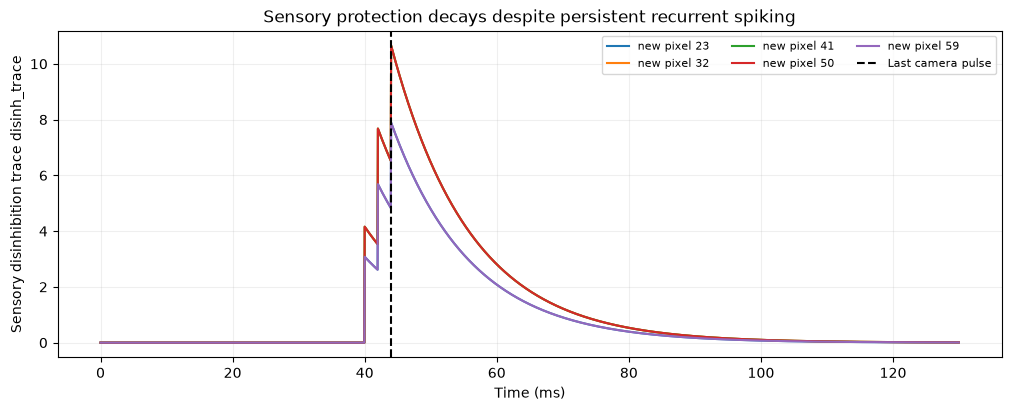

In [3]:
old, new = shapes["vertical"]
check = simulate([(old, (2., 4., 6.), 0.), (new, (40., 42., 44.), 0.)],
                 "sensory_spatial", record=True)
t = check["state_t"]
disinh_trace = check["states"]["disinh_trace"]
a, b = np.argmin(abs(t - 60.0)), np.argmin(abs(t - 120.0))
active = disinh_trace[:, a] > 0.01
ratio = disinh_trace[active, b] / disinh_trace[active, a]
expected = np.exp(-(t[b]-t[a])/tau_D_ms)
print(f"No-input decay: expected {expected:.5f}, observed mean {ratio.mean():.5f}")
assert np.allclose(ratio, expected, atol=1e-3, rtol=1e-2)
assert np.all(disinh_trace[:, b] < disinh_trace[:, a] + 1e-12)
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for pixel in new:
    ax.plot(t, disinh_trace[pixel], label=f"new pixel {pixel}")
ax.axvline(44, color="black", ls="--", label="Last camera pulse")
ax.set(xlabel="Time (ms)", ylabel="Sensory disinhibition trace disinh_trace",
       title="Sensory protection decays despite persistent recurrent spiking")
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.2)
plt.show()

## 4. Matched persistence and replacement experiments

We evaluate the five shapes that previously differentiated the frozen model. For each mechanism, run three controls: **old alone**, **new alone**, and **old followed by new**. Define persistence only if each pixel emits at least two spikes in **both** late windows; define complete suppression only if obsolete pixels emit **zero** spikes in both windows. Count off-target pixels separately. This avoids treating one transient sensory spike as sustained representation.

Because the sensory trace must disappear after input, the late-window results cannot be credited solely to ongoing disinhibition. Results for these five previously examined shapes remain *development-set* findings, not held-out generalization.

In [4]:
windows = ((90.0, 105.0), (105.0, 120.0))

def per_pixel(run, pixels_):
    return np.array([[np.count_nonzero((run["i"] == pixel) &
                    (run["t"] >= a) & (run["t"] < b))
                    for pixel in pixels_] for a, b in windows])

def evaluate(old, new, mechanism, row_delay=0., dt=0.05, tau_D=12., d0=2., alpha=0.15):
    controls = dict(mechanism=mechanism, row_delay=row_delay, dt=dt,
                    tau_D=tau_D, d0=d0, alpha=alpha)
    old_input = (old, (2., 4., 6.), row_delay)
    new_input = (new, (40., 42., 44.), row_delay)
    old_run = simulate([old_input], mechanism, dt, tau_D, d0, alpha)
    new_run = simulate([new_input], mechanism, dt, tau_D, d0, alpha)
    both = simulate([old_input, new_input], mechanism, dt, tau_D, d0, alpha)
    c_old = per_pixel(old_run, old)
    c_new = per_pixel(new_run, new)
    r_old = per_pixel(both, old)
    r_new = per_pixel(both, new)
    other = np.setdiff1d(np.arange(n), np.r_[old, new])
    r_other = per_pixel(both, other)
    metrics = dict(old_control=int((c_old >= 2).all(axis=0).sum()),
                   new_control=int((c_new >= 2).all(axis=0).sum()),
                   old_silent=int((r_old == 0).all(axis=0).sum()),
                   new_persistent=int((r_new >= 2).all(axis=0).sum()),
                   off_target=int((r_other > 0).any(axis=0).sum()))
    metrics["success"] = bool(metrics["old_control"] == 5 and
                               metrics["new_control"] == 5 and
                               metrics["old_silent"] == 5 and
                               metrics["new_persistent"] == 5 and
                               metrics["off_target"] == 0)
    return metrics

mechanisms = ("fixed", "sensory", "sensory_spatial")
rows = []
for mechanism in tqdm(mechanisms, desc="Compare mechanisms"):
    for geometry, (old, new) in shapes.items():
        rows.append(dict(mechanism=mechanism, geometry=geometry,
                         **evaluate(old, new, mechanism)))
comparison = pd.DataFrame(rows)
display(comparison)
display(comparison.groupby("mechanism").success.agg(["sum", "count"]))

Compare mechanisms:   0%|          | 0/3 [00:00<?, ?it/s]WARNING    The name "tau_D" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 12. * msecond, but the name also refers to a variable in the run namespace with value '12.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'disinh_trace' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(81, 2600)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'disinh_trace' is an internal variable of group 'neurongroup', but also exists in the r

,mechanism,geometry,old_control,new_control,old_silent,new_persistent,off_target,success
0,fixed,vertical,5,5,5,5,0,True
1,fixed,horizontal,5,5,5,5,0,True
2,fixed,diagonal,5,5,3,5,0,False
3,fixed,L shape,5,5,5,5,0,True
4,fixed,stepped,5,5,4,5,0,False
5,sensory,vertical,5,5,5,5,0,True
6,sensory,horizontal,5,5,5,5,0,True
7,sensory,diagonal,5,5,3,5,0,False
8,sensory,L shape,5,5,3,5,0,False
9,sensory,stepped,5,5,2,5,0,False


,sum,count
mechanism,,
fixed,3,5
sensory,2,5
sensory_spatial,0,5


## 5. Do the added signals protect the right population?

The mechanism should temporarily protect new sensory activity, **not preserve the old edge indefinitely**. Inspect the middle pixel of the old and new diagonal edge—one of the known failure geometries. Compare the recurrent inhibitory trace $I_{inh}$ and the effective inhibitory drive $I_{inh}/[1+D(1+\alpha S)]$.

If the new edge still fails to suppress old activity because the old pixels receive almost no inhibition, this mechanism cannot fix that structural deficit. If old activity survives longer, the added modulation is counterproductive. To avoid judging only by a binary pass, show the full raster and effective drive.

WARNING    'disinh_trace' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([0., 0., 0., ..., 0., 0., 0.], shape=(2600,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'support_trace' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([0., 0., 0., ..., 0., 0., 0.], shape=(2600,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'disinh_trace' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([0.        , 0.        , 0.        , ..., 0.00633797, 0.00631162,
       0.00628538], shape=(2600,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'support_trace' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 

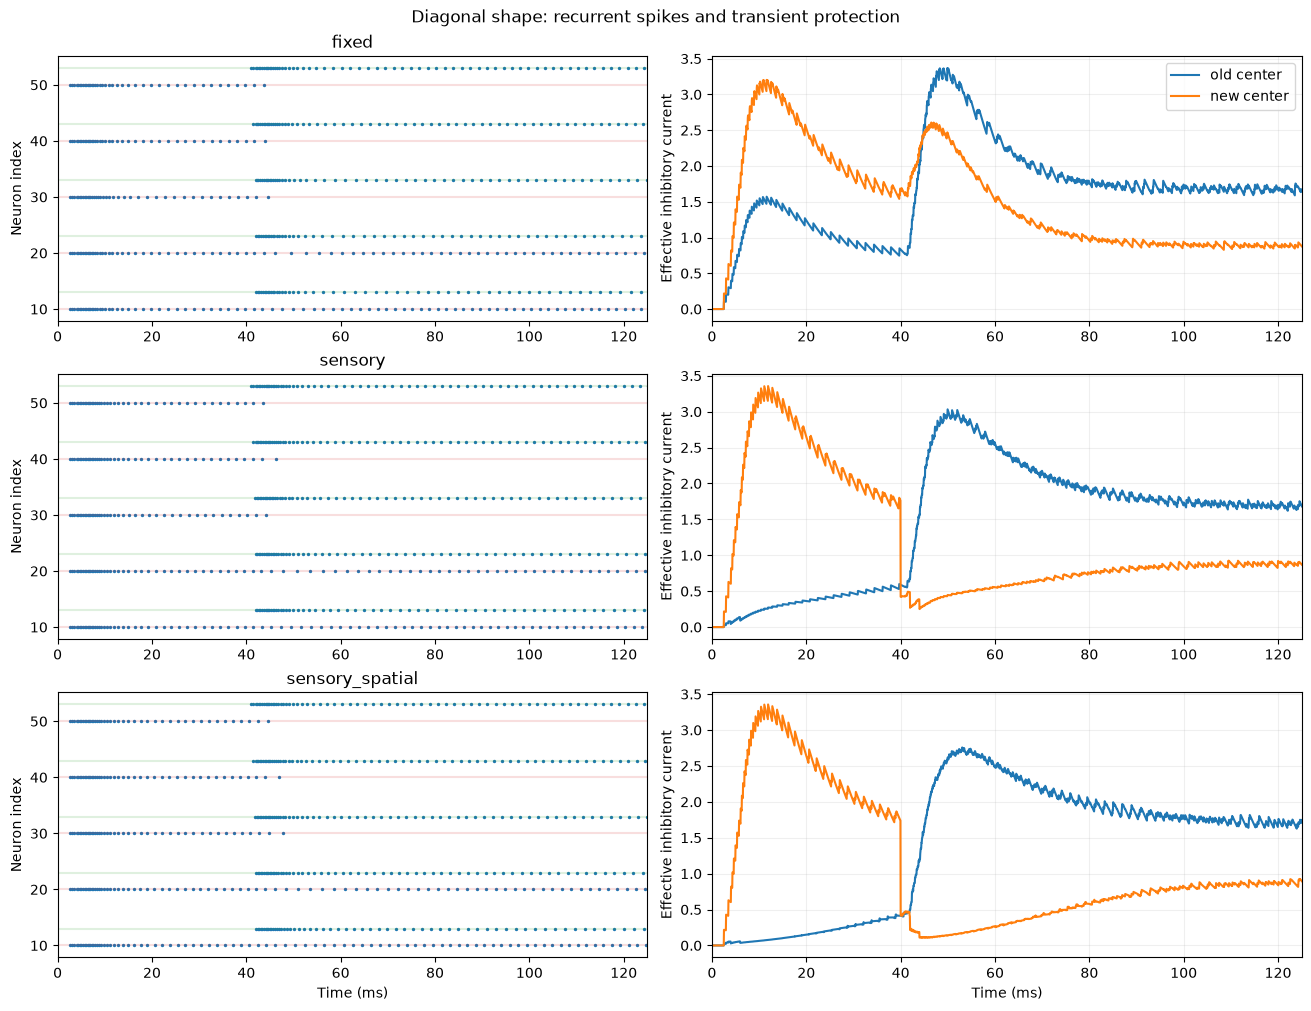

In [5]:
old, new = shapes["diagonal"]
protocol = [(old, (2., 4., 6.), 0.), (new, (40., 42., 44.), 0.)]
fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for row, mechanism in enumerate(mechanisms):
    r = simulate(protocol, mechanism, record=True)
    t = r["state_t"]
    center_old, center_new = old[2], new[2]
    for pixel, label in ((center_old, "old center"), (center_new, "new center")):
        disinh_trace = r["states"]["disinh_trace"][pixel]
        support_trace = r["states"]["support_trace"][pixel]
        denominator = (np.ones_like(disinh_trace) if mechanism == "fixed" else
                       1+disinh_trace if mechanism == "sensory" else
                       1+disinh_trace*(1+activity_gain*support_trace))
        axes[row, 1].plot(t, r["states"]["Iinh"][pixel]/denominator, label=label)
    axes[row, 0].scatter(r["t"], r["i"], s=2)
    for pixel in old:
        axes[row, 0].axhline(pixel, color="tab:red", alpha=0.15)
    for pixel in new:
        axes[row, 0].axhline(pixel, color="tab:green", alpha=0.15)
    axes[row, 0].set(title=mechanism, ylabel="Neuron index", xlim=(0, 125))
    axes[row, 1].set(ylabel="Effective inhibitory current", xlim=(0, 125))
    axes[row, 1].grid(alpha=0.2)
axes[0, 1].legend()
axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")
fig.suptitle("Diagonal shape: recurrent spikes and transient protection")
plt.show()

## 6. Bounded sensitivity and timestep controls

This is **not** a broad optimization. To distinguish a negative result caused by a too-short trace from one caused by the mechanism itself, examine two predeclared sensory timescales, $\tau_D\in\{8,20\}$ ms, with exactly the same gain and the same five development shapes. Do not choose new mechanisms or retune other network parameters based on these outcomes.

Finally, repeat the vertical and diagonal replacements for all three mechanisms at three timesteps (0.1, 0.05, 0.025 ms). A classification that changes under refinement is numerical sensitivity, not an improvement. Also recognize that threshold events can shift by one or more timesteps even when underlying continuous-time trajectories are converging.

In [6]:
sensitivity = []
for tau in tqdm((8.0, 20.0), desc="Disinhibition decay controls"):
    for mechanism in ("sensory", "sensory_spatial"):
        for geometry, (old, new) in shapes.items():
            sensitivity.append(dict(tau_D_ms=tau, mechanism=mechanism, geometry=geometry,
                                    **evaluate(old, new, mechanism, tau_D=tau)))
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity)
display(sensitivity.groupby(["tau_D_ms", "mechanism"]).success.agg(["sum", "count"]))

refinement = []
for dt in tqdm((0.1, 0.05, 0.025), desc="Numerical refinement"):
    for mechanism in mechanisms:
        for geometry in ("vertical", "diagonal"):
            old, new = shapes[geometry]
            refinement.append(dict(dt_ms=dt, mechanism=mechanism, geometry=geometry,
                                   **evaluate(old, new, mechanism, dt=dt)))
refinement = pd.DataFrame(refinement)
display(refinement)
display(refinement.pivot_table(index=["mechanism", "geometry"],
                                columns="dt_ms", values="success", aggfunc="first"))

Disinhibition decay controls:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    The name "tau_D" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 8. * msecond, but the name also refers to a variable in the run namespace with value '8.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'disinh_trace' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([0.        , 0.        , 0.        , ..., 0.00633797, 0.00631162,
       0.00628538], shape=(2600,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'support_trace' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([0.        , 0.        , 0.        , ..., 6.33018735, 6.29074705,
       6.54251295], shape=(2600,)). The i

,tau_D_ms,mechanism,geometry,old_control,new_control,old_silent,new_persistent,off_target,success
0,8.0,sensory,vertical,5,5,5,5,0,True
1,8.0,sensory,horizontal,5,5,5,5,0,True
2,8.0,sensory,diagonal,5,5,3,5,0,False
3,8.0,sensory,L shape,5,5,4,5,0,False
4,8.0,sensory,stepped,5,5,4,5,0,False
5,8.0,sensory_spatial,vertical,5,5,5,5,0,True
6,8.0,sensory_spatial,horizontal,5,5,5,5,0,True
7,8.0,sensory_spatial,diagonal,5,5,3,5,0,False
8,8.0,sensory_spatial,L shape,5,5,4,5,0,False
9,8.0,sensory_spatial,stepped,5,5,3,5,0,False


sum  count
tau_D_ms mechanism                  
8.0      sensory            2      5
         sensory_spatial    2      5
20.0     sensory            0      5
         sensory_spatial    0      5

Numerical refinement: 100%|██████████| 3/3 [00:27<00:00,  9.07s/it]


,dt_ms,mechanism,geometry,old_control,new_control,old_silent,new_persistent,off_target,success
0,0.100,fixed,vertical,5,5,5,5,0,True
1,0.100,fixed,diagonal,5,5,3,5,0,False
2,0.100,sensory,vertical,5,5,5,5,0,True
3,0.100,sensory,diagonal,5,5,3,5,0,False
4,0.100,sensory_spatial,vertical,5,5,1,5,0,False
5,0.100,sensory_spatial,diagonal,5,5,3,5,0,False
6,0.050,fixed,vertical,5,5,5,5,0,True
7,0.050,fixed,diagonal,5,5,3,5,0,False
8,0.050,sensory,vertical,5,5,5,5,0,True
9,0.050,sensory,diagonal,5,5,3,5,0,False


dt_ms                     0.025  0.050  0.100
mechanism       geometry                     
fixed           diagonal  False  False  False
                vertical   True   True   True
sensory         diagonal  False  False  False
                vertical   True   True   True
sensory_spatial diagonal  False  False  False
                vertical   True  False  False

## 7. Decision rule and limits

We will **not** replace the frozen reference merely because the modulation improves one plot. To justify further work, the new mechanism must (i) improve full replacement success across the predeclared shapes, (ii) preserve old-alone and new-alone persistence, (iii) avoid creating background activity, (iv) show disinhibition decaying after external input stops, and (v) retain its classification over the tested timesteps.

If neither variant satisfies these conditions, retain the frozen 5.5-pixel surround model and proceed to original-versus-refactor validation, as agreed. Regardless of outcome, the five geometries have been studied repeatedly and **cannot serve as an independent hold-out benchmark**. Any promising modulation should subsequently be tested on genuinely unseen stimuli and real event recordings.

The theoretical mechanism intentionally implements disinhibition as **temporary reduction of inhibitory efficacy**, rather than an explicit hand-designed winner switch. Nevertheless it remains a phenomenological extension; no inhibitory interneuron circuit or biological parameter fitting is established here.